Task 2.1

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def data_generator(n_samples=10, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.sort(np.random.uniform(0, 0.5, n_samples))
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 

    return t, y

data = data_generator(n_samples=10, m=1, k=500, mu=5)

data

(array([0.02904181, 0.07799726, 0.07800932, 0.18727006, 0.29932924,
        0.30055751, 0.35403629, 0.36599697, 0.43308807, 0.47535715]),
 array([ 0.80588718, -0.04163497, -0.04185532, -0.38790979,  0.4606251 ,
         0.45576153,  0.04111211, -0.06684187, -0.33953227, -0.15894969]))

In [2]:
import torch
from torch import nn
import torch.nn.functional as F


num_hidden = 100
num_features = 1
num_output = 1

class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()
        # Setting up variables, these variables are weights in your 
        # network that can be updated while running our graph.
        # Notice, to make a hidden layer, the weights need to have the 
        # following dimensionality:
        #   W[number_of_units_going_out, number_of_units_going_in]
        #   b[number_of_units_going_out]
        # in the example below we have 2 input units (num_features) and 2 output units (num_output)
        # so our weights become W[2, 2], b[2]
        # if we want to make a hidden layer with 100 units, we need to define the shape of the
        # first weight to W[100, 2], b[100] and the shape of the second weight to W[2, 100], b[2]
        
        # first layer
        self.W_1 = nn.Parameter(torch.randn(num_hidden, num_features)) 
        self.b_1 = nn.Parameter(torch.randn(num_hidden))
        
        # second layer (to be completed as an exercise)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        self.W_2 = nn.Parameter(torch.randn(num_output, num_hidden))
        self.b_2 = nn.Parameter(torch.randn(num_output))
        
        
    def forward(self, x):
        # Setting up ops, these ops will define edges along our computational graph
        # The below ops will compute a logistic regression, 
        # but can be modified to compute a neural network
        x = F.linear(x, self.W_1, self.b_1)
        
        # second layer (to be completed as an exercise)
        x = F.tanh(x)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        x = F.linear(x, self.W_2, self.b_2)
        return x 

net = Net()

In [3]:
import torch.optim as optim

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.005)


In [4]:



num_epochs = 10000
train_losses = []

# Convert data to tensors
tr_input = torch.from_numpy(data[0]).float().reshape(-1, 1)
print(tr_input)
tr_targets = torch.from_numpy(data[1]).float().reshape(-1, 1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

    # Prediction
    tr_output = net(tr_input)

    # Calculate loss
    tr_loss = criterion(tr_output, tr_targets)

    # Backpropagation
    tr_loss.backward()

    # Update weights
    optimizer.step()

    train_losses.append(tr_loss.data.numpy())

    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.item()))
print()

tensor([[0.0290],
        [0.0780],
        [0.0780],
        [0.1873],
        [0.2993],
        [0.3006],
        [0.3540],
        [0.3660],
        [0.4331],
        [0.4754]])
Epoch 0, Train Cost: 53.902458
Epoch 100, Train Cost: 0.132009
Epoch 200, Train Cost: 0.126002
Epoch 300, Train Cost: 0.125521
Epoch 400, Train Cost: 0.124977
Epoch 500, Train Cost: 0.124391
Epoch 600, Train Cost: 0.123782
Epoch 700, Train Cost: 0.123164
Epoch 800, Train Cost: 0.122547
Epoch 900, Train Cost: 0.121938
Epoch 1000, Train Cost: 0.121343
Epoch 1100, Train Cost: 0.120765
Epoch 1200, Train Cost: 0.120204
Epoch 1300, Train Cost: 0.119661
Epoch 1400, Train Cost: 0.119135
Epoch 1500, Train Cost: 0.118622
Epoch 1600, Train Cost: 0.118120
Epoch 1700, Train Cost: 0.117626
Epoch 1800, Train Cost: 0.117134
Epoch 1900, Train Cost: 0.116642
Epoch 2000, Train Cost: 0.116146
Epoch 2100, Train Cost: 0.115640
Epoch 2200, Train Cost: 0.115121
Epoch 2300, Train Cost: 0.114586
Epoch 2400, Train Cost: 0.114028
Epoch

In [5]:
np.random.seed(42)

def data_generator(n_samples=100, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.linspace(0, 1, n_samples+2)[1:-1]

    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 

    return t, y

colloc_data = data_generator(n_samples=100, m=1, k=500, mu=5)


In [6]:

plotting_data = data_generator(n_samples=100, m=1, k=500, mu=5)


In [7]:
te_input = torch.from_numpy(plotting_data[0]).float().reshape(-1, 1)
te_target = torch.from_numpy(plotting_data[1]).float().reshape(-1, 1)


with torch.no_grad():
    te_output = net(te_input)


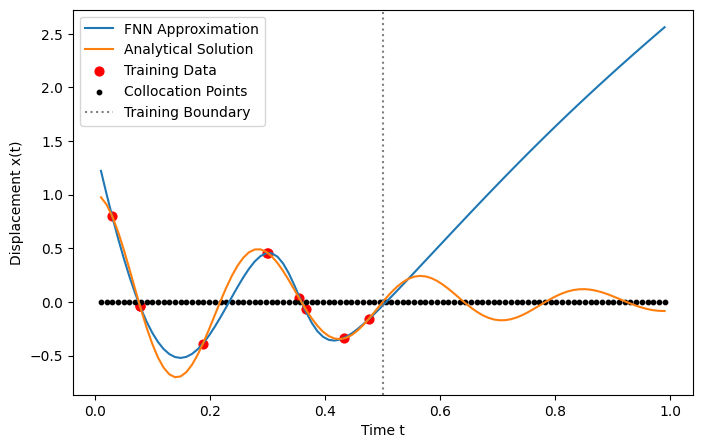

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(te_input,te_output, label="FNN Approximation")
plt.plot(te_input,te_target, label="Analytical Solution")
plt.scatter(data[0], data[1], color="red", label="Training Data", s=40)
plt.scatter(colloc_data[0], np.zeros(len(colloc_data[0])), color="black", label="Collocation Points", s=10)
plt.axvline(0.5, color="gray", linestyle=":", label="Training Boundary")
plt.xlabel("Time t")
plt.ylabel("Displacement x(t)")
plt.legend()
plt.show()


it gets crazy since the net is only trained on the interval 0-0.5, so it does not know at all after this. 

In [9]:

def loss(net, data_input, data_target, colloc_input, lambda_phys=1.0, lambda_IC=1.0):

    data_out= net(data_input)
    colloc_out=net(colloc_input)

    W1 = net.W_1
    W2 = net.W_2
    b1 = net.b_1
    b2 = net.b_2

    a=F.linear(colloc_input, W1, b1)

    L_data= nn.MSELoss()(data_out,data_target)

    tanh_a= torch.tanh(a)
    tanh_a_d= 1 - tanh_a**2
    tanh_a_dd = -2*tanh_a*tanh_a_d

   
    x_d= (W2 * tanh_a_d) @ W1

    x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

    residual = x_dd + 5*x_d + 500*colloc_out

    L_phys = nn.MSELoss()(residual, torch.zeros_like(residual))

 

    L_IC1= ((W2@torch.tanh(b1)+b2)-1)**2

    L_IC2= (W2*(1 - torch.tanh(b1)**2)@W1)**2

    L_IC= L_IC1 + L_IC2

    L_total= L_data + lambda_phys*L_phys + lambda_IC*L_IC

    return L_data, L_phys, L_IC, L_total



In [10]:
## finite difference calculations


data_input=torch.from_numpy(data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(colloc_data[0]).float().reshape(-1, 1)

torch.manual_seed(42)
net = Net()

epsilon= 10**(-5)

with torch.no_grad():
    net.W_1[4,0]=net.W_1[4,0]+epsilon

loss_plus = loss(net, data_input, data_target, colloc_input, lambda_phys=1.0, lambda_IC=1.0)[3]

with torch.no_grad():
    net.W_1[4,0]=net.W_1[4,0]-2*epsilon

loss_minus = loss(net, data_input, data_target, colloc_input, lambda_phys=1.0, lambda_IC=1.0)[3]

loss_approx = (loss_plus- loss_minus)/(2*epsilon)

loss_approx



tensor([[-6250.]], grad_fn=<DivBackward0>)

In [11]:
## Analytical gradient calculations

# go back to the original value of W_1[4,0]
with torch.no_grad():
    net.W_1[4,0]=net.W_1[4,0]+epsilon

# Initial definitions for calculations of all gradients
W1 = net.W_1
W2 = net.W_2
b1 = net.b_1
b2 = net.b_2

data_out= net(data_input)
colloc_out = net(colloc_input)

a=F.linear(colloc_input, W1, b1)

b=F.linear(data_input, W1, b1)


tanh_a= torch.tanh(a)
tanh_a_d= 1 - tanh_a**2
tanh_a_dd = -2*tanh_a*tanh_a_d
tanh_a_ddd = -2*tanh_a_d**2 -2*tanh_a*tanh_a_dd

tanh_b= torch.tanh(b)
tanh_b_d= 1 - tanh_b**2
tanh_b_dd = -2*tanh_b*tanh_b_d
tanh_b_ddd = -2*tanh_b_d**2 -2*tanh_b*tanh_b_dd

   
x_d= (W2 * tanh_a_d) @ W1
x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

residual = x_dd + 5*x_d + 500*colloc_out

lambda_phys=1
lambda_IC= 1

## gradient of loss w.r.t W1

r1_d_W1 = (W2 * tanh_a_dd * W1.T+ W1.T * (W2 * tanh_a_dd+ W2 * tanh_a_ddd * colloc_input * W1.T))
r2_d_W1 = 5*((W2*tanh_a_d) + W2*tanh_a_dd*colloc_input*W1.T)
r3_d_W1 = 500*(W2*tanh_a_d)*colloc_input

residual_d_W1= r1_d_W1 + r2_d_W1 + r3_d_W1


##g_data_W1 = 2*torch.mean((data_out-data_target)*((W2*tanh_b_d).T*data_input), dim=0)

g_data_W1 = 2 * torch.mean((data_out - data_target) *(W2 * tanh_b_d) *data_input,dim=0).reshape_as(W1)

g_phys_W1 = 2*torch.mean(residual*residual_d_W1, dim=0).reshape_as(W1)

g_IC1_W1 = torch.zeros_like(W1)
g_IC2_W1 = (2*((W2*(1 - torch.tanh(b1)**2)) @ W1)* (W2 * (1 - torch.tanh(b1)**2)).T)
g_IC_W1= g_IC1_W1 + g_IC2_W1

g_total_W1 = g_data_W1 + lambda_phys*g_phys_W1 + lambda_IC*g_IC_W1 

print(g_total_W1[4,0])

print("W1:", W1.shape)
print("Data:", g_data_W1.shape)
print("Physics:", g_phys_W1.shape)
print("IC:", g_IC_W1.shape)
print("Total:", g_total_W1.shape)

tensor(-9469.6357, grad_fn=<SelectBackward0>)
W1: torch.Size([100, 1])
Data: torch.Size([100, 1])
Physics: torch.Size([100, 1])
IC: torch.Size([100, 1])
Total: torch.Size([100, 1])


In [12]:
## gradient of loss w.r.t W2

r1_d_W2 = W1.T**2* (tanh_a_dd)
r2_d_W2 = 5*(tanh_a_d*W1.T)
r3_d_W2 = 500*(tanh_a)

residual_d_W2= r1_d_W2 + r2_d_W2 + r3_d_W2

g_data_W2 = 2 * torch.mean((data_out - data_target) * tanh_b,dim=0).reshape_as(W2)

g_phys_W2 = 2*torch.mean(residual*residual_d_W2, dim=0).reshape_as(W2)

g_IC1_W2 = (2 * (W2 @ torch.tanh(b1).reshape(-1, 1) + b2 - 1)* torch.tanh(b1).reshape(1, -1))
g_IC2_W2 = (2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)* ((1 - torch.tanh(b1)**2) * W1.T))
g_IC_W2= g_IC1_W2 + g_IC2_W2

g_total_W2 = g_data_W2 + lambda_phys*g_phys_W2 + lambda_IC*g_IC_W2 

print("W2:", W2.shape)
print("Data:", g_data_W2.shape)
print("Physics:", g_phys_W2.shape)
print("IC1:", g_IC1_W2.shape)
print("IC2:", g_IC2_W2.shape)
print("Total:", g_total_W2.shape)

W2: torch.Size([1, 100])
Data: torch.Size([1, 100])
Physics: torch.Size([1, 100])
IC1: torch.Size([1, 100])
IC2: torch.Size([1, 100])
Total: torch.Size([1, 100])


In [13]:
## Analytical gradient calculations

## gradient of loss w.r.t b1
r1_d_b1 = W1.T**2* W2*(tanh_a_ddd)
r2_d_b1 = 5*W2*tanh_a_dd*W1.T
r3_d_b1 = 500*(W2*tanh_a_d)

residual_d_b1= r1_d_b1 + r2_d_b1 + r3_d_b1

g_data_b1 = 2 * torch.mean((data_out - data_target) * W2*tanh_b_d,dim=0).reshape_as(b1)

g_phys_b1 = 2*torch.mean(residual*residual_d_b1, dim=0).reshape_as(b1)

g_IC1_b1 = (2 * (W2 @ torch.tanh(b1).reshape(-1, 1) + b2 - 1)* W2*(1 - torch.tanh(b1)**2)).reshape_as(b1)
g_IC2_b1 = (2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)* (W2*(-2*(torch.tanh(b1))*(1 - torch.tanh(b1)**2)) * W1.T)).reshape_as(b1)
g_IC_b1= g_IC1_b1 + g_IC2_b1

g_total_b1 = g_data_b1 + lambda_phys*g_phys_b1 + lambda_IC*g_IC_b1 

print("b1:", b1.shape)
print("Data:", g_data_b1.shape)
print("Physics:", g_phys_b1.shape)
print("IC1:", g_IC1_b1.shape)
print("IC2:", g_IC2_b1.shape)
print("Total:", g_total_b1.shape)

b1: torch.Size([100])
Data: torch.Size([100])
Physics: torch.Size([100])
IC1: torch.Size([100])
IC2: torch.Size([100])
Total: torch.Size([100])


In [14]:
## Analytical gradient calculations

## gradient of loss w.r.t b2

r1_d_b2 = 0
r2_d_b2 = 0
r3_d_b2 = 500*1

residual_d_b2= r1_d_b2 + r2_d_b2 + r3_d_b2

g_data_b2 = 2 * torch.mean((data_out - data_target), dim=0)

g_phys_b2 = 2*torch.mean(residual*residual_d_b2, dim=0)

g_IC1_b2 = (2 * (W2 @ torch.tanh(b1) + b2 - 1)* 1)
g_IC2_b2 = torch.zeros_like(b2)
g_IC_b2= g_IC1_b2 + g_IC2_b2

g_total_b2 = g_data_b2 + lambda_phys*g_phys_b2 + lambda_IC*g_IC_b2 

print("b2:", b2.shape)
print("Data:", g_data_b2.shape)
print("Physics:", g_phys_b2.shape)
print("IC1:", g_IC1_b2.shape)
print("IC2:", g_IC2_b2.shape)
print("Total:", g_total_b2.shape)

b2: torch.Size([1])
Data: torch.Size([1])
Physics: torch.Size([1])
IC1: torch.Size([1])
IC2: torch.Size([1])
Total: torch.Size([1])


In [15]:
# Her samler vi bare de analystiske gradienter vi lavede før i en funktion der regner dem alle på en gang.

def analytical_grads(net, data_input, data_target, colloc_input,
                     lambda_phys=1.0, lambda_IC=1.0):

    W1 = net.W_1
    W2 = net.W_2
    b1 = net.b_1
    b2 = net.b_2

    data_out = net(data_input)
    colloc_out = net(colloc_input)

    a = F.linear(colloc_input, W1, b1)
    b = F.linear(data_input, W1, b1)

    tanh_a = torch.tanh(a)
    tanh_a_d = 1 - tanh_a**2
    tanh_a_dd = -2*tanh_a*tanh_a_d
    tanh_a_ddd = -2*tanh_a_d**2 - 2*tanh_a*tanh_a_dd

    tanh_b = torch.tanh(b)
    tanh_b_d = 1 - tanh_b**2

    x_d = (W2 * tanh_a_d) @ W1
    x_dd = ((W1.T * W2) * tanh_a_dd) @ W1

    residual = x_dd + 5*x_d + 500*colloc_out

    ## gradient of loss w.r.t W1

    r1_d_W1 = (W2 * tanh_a_dd * W1.T + W1.T * (W2 * tanh_a_dd + W2 * tanh_a_ddd * colloc_input * W1.T))
    r2_d_W1 = 5*((W2*tanh_a_d) + W2*tanh_a_dd*colloc_input*W1.T)
    r3_d_W1 = 500*(W2*tanh_a_d)*colloc_input

    residual_d_W1 = r1_d_W1 + r2_d_W1 + r3_d_W1

    g_data_W1 = 2 * torch.mean((data_out - data_target) * (W2 * tanh_b_d) * data_input, dim=0).reshape_as(W1)
    g_phys_W1 = 2 * torch.mean(residual*residual_d_W1, dim=0).reshape_as(W1)

    g_IC1_W1 = torch.zeros_like(W1)
    g_IC2_W1 = (2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)* (W2 * (1 - torch.tanh(b1)**2)).T)
    g_IC_W1 = g_IC1_W1 + g_IC2_W1

    g_total_W1 = g_data_W1 + lambda_phys*g_phys_W1 + lambda_IC*g_IC_W1
    

    ## gradient of loss w.r.t W2

    r1_d_W2 = W1.T**2 * tanh_a_dd
    r2_d_W2 = 5*(tanh_a_d*W1.T)
    r3_d_W2 = 500*tanh_a

    residual_d_W2 = r1_d_W2 + r2_d_W2 + r3_d_W2

    g_data_W2 = 2 * torch.mean((data_out - data_target) * tanh_b, dim=0).reshape_as(W2)
    g_phys_W2 = 2 * torch.mean(residual*residual_d_W2, dim=0).reshape_as(W2)

    g_IC1_W2 = (
        2 * (W2 @ torch.tanh(b1).reshape(-1, 1) + b2 - 1)
        * torch.tanh(b1).reshape(1, -1)
    )
    g_IC2_W2 = (
        2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)
        * ((1 - torch.tanh(b1)**2) * W1.T)
    )
    g_IC_W2 = g_IC1_W2 + g_IC2_W2

    g_total_W2 = g_data_W2 + lambda_phys*g_phys_W2 + lambda_IC*g_IC_W2
    

    ## gradient of loss w.r.t b1

    r1_d_b1 = W1.T**2 * W2 * tanh_a_ddd
    r2_d_b1 = 5*(W2*tanh_a_dd*W1.T)
    r3_d_b1 = 500*(W2*tanh_a_d)

    residual_d_b1 = r1_d_b1 + r2_d_b1 + r3_d_b1

    g_data_b1 = 2 * torch.mean(
        (data_out - data_target) * W2*tanh_b_d, dim=0
    ).reshape_as(b1)
    g_phys_b1 = 2 * torch.mean(residual*residual_d_b1, dim=0).reshape_as(b1)

    g_IC1_b1 = (
        2 * (W2 @ torch.tanh(b1).reshape(-1, 1) + b2 - 1)
        * W2 * (1 - torch.tanh(b1)**2)
    ).reshape_as(b1)
    g_IC2_b1 = (
        2 * ((W2 * (1 - torch.tanh(b1)**2)) @ W1)
        * (W2 * (-2*torch.tanh(b1)*(1 - torch.tanh(b1)**2)) * W1.T)
    ).reshape_as(b1)
    g_IC_b1 = g_IC1_b1 + g_IC2_b1

    g_total_b1 = g_data_b1 + lambda_phys*g_phys_b1 + lambda_IC*g_IC_b1
    

    ## gradient of loss w.r.t b2

    r1_d_b2 = 0
    r2_d_b2 = 0
    r3_d_b2 = 500*1

    residual_d_b2 = r1_d_b2 + r2_d_b2 + r3_d_b2

    g_data_b2 = 2 * torch.mean(data_out - data_target, dim=0)
    g_phys_b2 = 2 * torch.mean(residual*residual_d_b2, dim=0)

    g_IC1_b2 = 2 * (W2 @ torch.tanh(b1) + b2 - 1) * 1
    g_IC2_b2 = torch.zeros_like(b2)
    g_IC_b2 = g_IC1_b2 + g_IC2_b2

    g_total_b2 = g_data_b2 + lambda_phys*g_phys_b2 + lambda_IC*g_IC_b2

    return g_total_W1, g_total_W2, g_total_b1, g_total_b2

In [16]:
# Nu træner vi så netværket ved brug af de gradienter
optimizer = optim.Adam(net.parameters(), lr=0.005)

num_epochs = 10000
train_losses = []
data_losses = []
phys_losses = []
IC_losses = []

lambda_phys = 0.00001
lambda_IC = 1
data_input=torch.from_numpy(data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(colloc_data[0]).float().reshape(-1, 1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

    with torch.no_grad():
        # Calculate loss. (vha. den loss funktion vi definerede tidligere)
        L_data, L_phys, L_IC, tr_loss = loss(
            net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
        )

        # Calculate analytical gradients
        g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads(
            net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
        )

    # Give the gradients to the optimizer
    net.W_1.grad = g_total_W1
    net.W_2.grad = g_total_W2
    net.b_1.grad = g_total_b1
    net.b_2.grad = g_total_b2

    # Update weights
    optimizer.step()
    

    train_losses.append(tr_loss.numpy().reshape(()))
    data_losses.append(L_data.numpy())
    phys_losses.append(lambda_phys * L_phys.numpy())
    IC_losses.append(lambda_IC * L_IC.numpy().reshape(()))


    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.numpy()))

Epoch 0, Train Cost: 67.320572
Epoch 100, Train Cost: 0.581823


/var/folders/5k/116cls7n39lg8247klckxrm80000gn/T/ipykernel_70345/3509710063.py:49: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.numpy()))


Epoch 200, Train Cost: 0.565586
Epoch 300, Train Cost: 0.551285
Epoch 400, Train Cost: 0.539216
Epoch 500, Train Cost: 0.529829
Epoch 600, Train Cost: 0.522780
Epoch 700, Train Cost: 0.517444
Epoch 800, Train Cost: 0.513199
Epoch 900, Train Cost: 0.509542
Epoch 1000, Train Cost: 0.506112
Epoch 1100, Train Cost: 0.502689
Epoch 1200, Train Cost: 0.499145
Epoch 1300, Train Cost: 0.495412
Epoch 1400, Train Cost: 0.491458
Epoch 1500, Train Cost: 0.487261
Epoch 1600, Train Cost: 0.482802
Epoch 1700, Train Cost: 0.478045
Epoch 1800, Train Cost: 0.472925
Epoch 1900, Train Cost: 0.467338
Epoch 2000, Train Cost: 0.461131
Epoch 2100, Train Cost: 0.454093
Epoch 2200, Train Cost: 0.445946
Epoch 2300, Train Cost: 0.436368
Epoch 2400, Train Cost: 0.425079
Epoch 2500, Train Cost: 0.412014
Epoch 2600, Train Cost: 0.397454
Epoch 2700, Train Cost: 0.381982
Epoch 2800, Train Cost: 0.366252
Epoch 2900, Train Cost: 0.350807
Epoch 3000, Train Cost: 0.335909
Epoch 3100, Train Cost: 0.321650
Epoch 3200, Train 

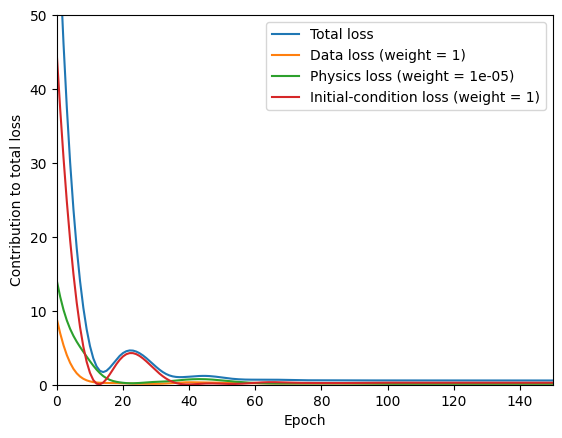

Last recorded total loss: 0.034203
Data contribution:        0.021126
Physics contribution:     0.012811
IC contribution:          0.000266


In [17]:
#Nu plotter vi så de forskellige bidrag til loss'en over tid, så vi kan se hvordan de forskellige bidrag udvikler sig under træningen.

plt.plot(train_losses, label="Total loss")
plt.plot(data_losses, label="Data loss (weight = 1)")
plt.plot(phys_losses, label="Physics loss (weight = %g)" % lambda_phys)
plt.plot(IC_losses, label="Initial-condition loss (weight = %g)" % lambda_IC)

plt.xlabel("Epoch")
plt.ylabel("Contribution to total loss")
plt.xlim([0, 150])
plt.ylim([0, 50])
plt.legend()
plt.show()

print("Last recorded total loss: %0.6f" % train_losses[-1])
print("Data contribution:        %0.6f" % data_losses[-1])
print("Physics contribution:     %0.6f" % phys_losses[-1])
print("IC contribution:          %0.6f" % IC_losses[-1])

# Måske vi så skulle overveje at give de forskellige bidrag til loss'en forskellige weights, så vi kan få dem til at bidrage mere ligeværdigt til den samlede loss?

In [18]:
# Nu laver vi en funktion der træner et netværk for givne regularization vægte (lambdaer) og returnerer det trænede netværk så vi kan bruge de trænede netværk til forudsigelser.

def train_pinn(data_input, data_target, colloc_input, lambda_phys, lambda_IC=1.0, num_epochs=10000):
    torch.manual_seed(42) #vi sørger for at de bliver initialiset ens
    net = Net()
    optimizer = optim.Adam(net.parameters(), lr=0.005)
    
    # Training loop
    for e in range(num_epochs):

        optimizer.zero_grad()

        with torch.no_grad():
            # Calculate loss. (vha. den loss funktion vi definerede tidligere)
            L_data, L_phys, L_IC, tr_loss = loss(
                net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
            )

            # Calculate analytical gradients
            g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads(
                net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
            )

        # Give the gradients to the optimizer
        net.W_1.grad = g_total_W1
        net.W_2.grad = g_total_W2
        net.b_1.grad = g_total_b1
        net.b_2.grad = g_total_b2

        # Update weights
        optimizer.step()
    return net

In [19]:
# Nu der prøver vi så at træne for to forskellige værdier af lambda_phys (en stor og en lille))
lambda_phys_weak= 0.00000001
lambda_phys_strong= 0.00001

lambda_IC_weak= 0.001
lambda_IC_strong= 1
net_weak= train_pinn(data_input, data_target, colloc_input,lambda_phys_weak, lambda_IC_weak)
net_strong= train_pinn(data_input, data_target, colloc_input, lambda_phys_strong, lambda_IC_strong)



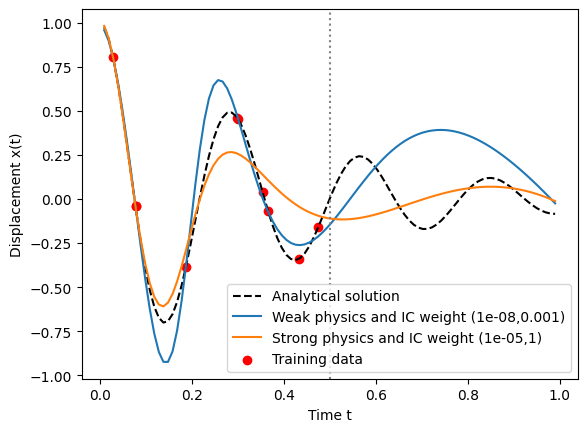

In [20]:
te_target = torch.from_numpy(plotting_data[1]).float().reshape(-1, 1)
te_input= torch.from_numpy(plotting_data[0]).float().reshape(-1, 1)

# så bruger vi de to trænede netværk til at lave forudsigelser på test dataen og sammenligner med den sande test data te_target.
with torch.no_grad():
    te_output_weak = net_weak(te_input).numpy().reshape(-1)
    te_output_strong = net_strong(te_input).numpy().reshape(-1)

t= te_input.numpy().reshape(-1)

# og plot den analytiske løsning, de to forudsigelser og træningsdataen.
plt.plot(t, te_target, "k--", label="Analytical solution")
plt.plot(t, te_output_weak, label="Weak physics and IC weight (%g," % lambda_phys_weak +"%g)" % lambda_IC_weak)
plt.plot(t, te_output_strong, label="Strong physics and IC weight (%g," % lambda_phys_strong + "%g)" % lambda_IC_strong)
plt.scatter(data[0], data[1], color="red", label="Training data")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlabel("Time t")
plt.ylabel("Displacement x(t)")
plt.legend()
plt.show()


In [21]:
## Repeating training from previous task now using torch.autograd.grad to compute the parameter gradients
torch.manual_seed(42)
net = Net()
optimizer = optim.Adam(net.parameters(), lr=0.005)

num_epochs = 10000
train_losses_auto = []
data_losses_auto = []
phys_losses_auto = []
IC_losses_auto = []

lambda_phys = 0.00001
lambda_IC = 1
data_input=torch.from_numpy(data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(colloc_data[0]).float().reshape(-1, 1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

   
    # Calculate loss. (vha. den loss funktion vi definerede tidligere)
    L_data, L_phys, L_IC, tr_loss = loss(
        net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
    )

    # backward
    tr_loss.backward()

    # Update weights
    optimizer.step()
    

    train_losses_auto.append(tr_loss.item())
    data_losses_auto.append(L_data.item())
    phys_losses_auto.append(lambda_phys * L_phys.item())
    IC_losses_auto.append(lambda_IC * L_IC.item())


    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.item()))



Epoch 0, Train Cost: 67.320572
Epoch 100, Train Cost: 0.581823
Epoch 200, Train Cost: 0.565586
Epoch 300, Train Cost: 0.551286
Epoch 400, Train Cost: 0.539217
Epoch 500, Train Cost: 0.529829
Epoch 600, Train Cost: 0.522780
Epoch 700, Train Cost: 0.517444
Epoch 800, Train Cost: 0.513199
Epoch 900, Train Cost: 0.509542
Epoch 1000, Train Cost: 0.506112
Epoch 1100, Train Cost: 0.502689
Epoch 1200, Train Cost: 0.499144
Epoch 1300, Train Cost: 0.495411
Epoch 1400, Train Cost: 0.491458
Epoch 1500, Train Cost: 0.487261
Epoch 1600, Train Cost: 0.482801
Epoch 1700, Train Cost: 0.478045
Epoch 1800, Train Cost: 0.472925
Epoch 1900, Train Cost: 0.467339
Epoch 2000, Train Cost: 0.461132
Epoch 2100, Train Cost: 0.454093
Epoch 2200, Train Cost: 0.445947
Epoch 2300, Train Cost: 0.436368
Epoch 2400, Train Cost: 0.425080
Epoch 2500, Train Cost: 0.412014
Epoch 2600, Train Cost: 0.397455
Epoch 2700, Train Cost: 0.381983
Epoch 2800, Train Cost: 0.366252
Epoch 2900, Train Cost: 0.350802
Epoch 3000, Train Cos

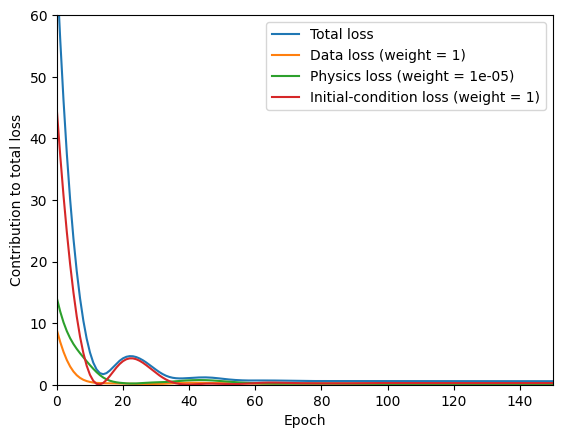

Last recorded total loss: 0.036632
Data contribution:        0.022949
Physics contribution:     0.012298
IC contribution:          0.001386


In [22]:
#Nu plotter vi så de forskellige bidrag til loss'en over tid, så vi kan se hvordan de forskellige bidrag udvikler sig under træningen.

plt.plot(train_losses_auto, label="Total loss")
plt.plot(data_losses_auto, label="Data loss (weight = 1)")
plt.plot(phys_losses_auto, label="Physics loss (weight = %g)" % lambda_phys)
plt.plot(IC_losses_auto, label="Initial-condition loss (weight = %g)" % lambda_IC)

plt.xlabel("Epoch")
plt.ylabel("Contribution to total loss")
plt.xlim([0, 150])
plt.ylim([0, 60])
plt.legend()
plt.show()

print("Last recorded total loss: %0.6f" % train_losses_auto[-1])
print("Data contribution:        %0.6f" % data_losses_auto[-1])
print("Physics contribution:     %0.6f" % phys_losses_auto[-1])
print("IC contribution:          %0.6f" % IC_losses_auto[-1])


In [23]:
## Relativ fejl af gradienter (autograd vs. analytical) ved initialisering 


torch.manual_seed(42)
net=Net()

## analytic gradients

with torch.no_grad():
    # Calculate analytical gradients
    g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads(
        net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
    )

# Calculate loss. (vha. den loss funktion vi definerede tidligere)
L_data, L_phys, L_IC, tr_loss = loss(
    net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
)


## automatic gradients

grads_autograd = torch.autograd.grad(tr_loss, (net.W_1, net.W_2, net.b_1, net.b_2))




rel_error_W1 = (
    torch.linalg.norm(g_total_W1-grads_autograd[0])
    / torch.linalg.norm(grads_autograd[0])
)

rel_error_W2 = (
    torch.linalg.norm(g_total_W2-grads_autograd[1])
    / torch.linalg.norm(grads_autograd[1])
)

rel_error_b1 = (
    torch.linalg.norm(g_total_b1-grads_autograd[2])
    / torch.linalg.norm(grads_autograd[2])
)

rel_error_b2 = (
    torch.linalg.norm(g_total_b2-grads_autograd[3])
    / torch.linalg.norm(grads_autograd[3])
)


print(rel_error_W1,rel_error_W2,rel_error_b1,rel_error_b2)





tensor(9.3445e-08) tensor(6.2751e-08) tensor(8.1726e-08) tensor(0.)


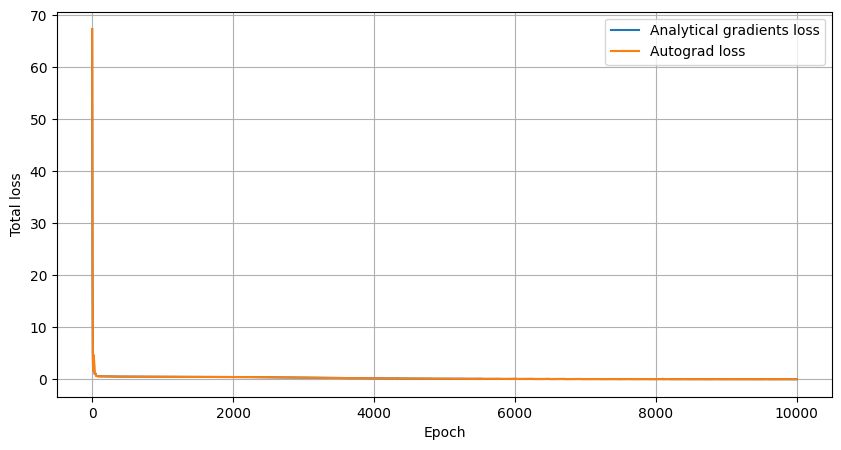

In [24]:
plt.figure(figsize=(10, 5))


plt.plot(train_losses, label="Analytical gradients loss")
plt.plot(train_losses_auto, label="Autograd loss")

plt.xlabel("Epoch")
plt.ylabel("Total loss")
##plt.yscale("log")
plt.legend()
plt.grid()
plt.show()

In [25]:
def train_autograd_pinn(data_input, data_target, colloc_input, lambda_phys, lambda_IC=1.0, num_epochs=10000):
    torch.manual_seed(42) #vi sørger for at de bliver initialiset ens
    net = Net()
    optimizer = optim.Adam(net.parameters(), lr=0.005)


    # Training loop
    for e in range(num_epochs):

        optimizer.zero_grad()

      
        # Calculate loss. (vha. den loss funktion vi definerede tidligere)
        L_data, L_phys, L_IC, tr_loss = loss(
            net, data_input, data_target, colloc_input, lambda_phys, lambda_IC
        )

        # Backpropagation
        tr_loss.backward()

        # Update weights
        optimizer.step()
    
        
    return net

In [ ]:
# Nu der prøver vi så at træne for to forskellige værdier af lambda_phys (en stor og en lille))

## argumenter for vores valg af lambda. phys dominerer voldsomt, så hvis man overhovedet skal se en ændring i lambda for IC skal de være langt større end for phys
lambda_phys_weak= 0.00000001
lambda_phys_strong= 0.00001

lambda_IC_weak= 0.001
lambda_IC_strong= 1


net_weak_auto= train_autograd_pinn(data_input, data_target, colloc_input, lambda_phys_weak, lambda_IC_weak)
net_strong_auto= train_autograd_pinn(data_input, data_target, colloc_input, lambda_phys_strong, lambda_IC_strong)

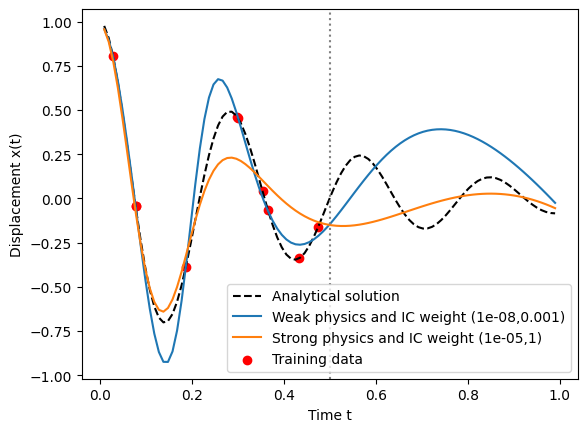

In [ ]:
te_target = torch.from_numpy(plotting_data[1]).float().reshape(-1, 1)
te_input= torch.from_numpy(plotting_data[0]).float().reshape(-1, 1)

# så bruger vi de to trænede netværk til at lave forudsigelser på test dataen og sammenligner med den sande test data te_target.
with torch.no_grad():
    te_output_weak_auto = net_weak_auto(te_input).numpy().reshape(-1)
    te_output_strong_auto = net_strong_auto(te_input).numpy().reshape(-1)

t= te_input.numpy().reshape(-1)

# og plot den analytiske løsning, de to forudsigelser og træningsdataen.
plt.plot(t, te_target, "k--", label="Analytical solution")
plt.plot(t, te_output_weak_auto, label="Weak physics and IC weight (%g," % lambda_phys_weak + "%g)" % lambda_IC_weak)
plt.plot(t, te_output_strong_auto, label="Strong physics and IC weight (%g," % lambda_phys_strong + "%g)" % lambda_IC_strong)
plt.scatter(data[0], data[1], color="red", label="Training data")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlabel("Time t")
plt.ylabel("Displacement x(t)")
plt.legend()
plt.show()


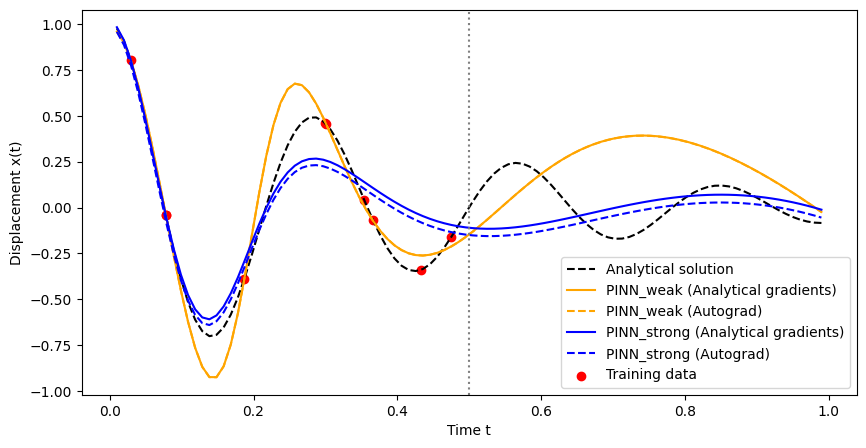

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(t, te_target, "k--", label="Analytical solution")
plt.plot(t, te_output_weak, color="orange", label="PINN_weak (Analytical gradients)")
plt.plot(t, te_output_weak_auto, "--", color="orange", label="PINN_weak (Autograd)")
plt.plot(t, te_output_strong, color="blue",label="PINN_strong (Analytical gradients)")
plt.plot(t, te_output_strong_auto, "--",color="blue", label="PINN_strong (Autograd)")

plt.scatter(data[0], data[1], color="red", label="Training data")
plt.axvline(0.5, color="gray", linestyle=":")

plt.xlabel("Time t")
plt.ylabel("Displacement x(t)")
plt.legend()
plt.show()

In [ ]:
## task 2.7
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def data_generator(n_samples=10, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.sort(np.random.uniform(0, 0.5, n_samples))
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 

    return t, y 

data_hard_data = data_generator(n_samples=10, m=1, k=500, mu=5)

np.random.seed(42)

def data_generator(n_samples=10, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.linspace(0,1, n_samples+2)[1:-1]
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t)*(2*A*np.cos(phi+omega*t)) 


    return t, y 

data_hard_colloc = data_generator(n_samples=100, m=1, k=500, mu=5)


In [ ]:

def loss_hard(net, data_input, data_target, colloc_input, lambda_phys=1.0):

    data_out= net(data_input)
    colloc_out=net(colloc_input)

    W1 = net.W_1
    W2 = net.W_2
    b1 = net.b_1
    b2 = net.b_2

    a=F.linear(colloc_input, W1, b1)

    L_data= nn.MSELoss()(torch.ones_like(data_out)+data_out*data_input**2,data_target)

    tanh_a= torch.tanh(a)
    tanh_a_d= 1 - tanh_a**2
    tanh_a_dd = -2*tanh_a*tanh_a_d

    x_d= (W2 * tanh_a_d) @ W1
    x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

    x_hat= colloc_out*colloc_input**2 +torch.ones_like(colloc_out)
    x_d_hat= 2*colloc_input*colloc_out + x_d*colloc_input**2
    x_dd_hat= 2*colloc_out + 4*x_d*colloc_input + x_dd*colloc_input**2

    residual = x_dd_hat + 5*x_d_hat + 500*x_hat

    L_phys = nn.MSELoss()(residual, torch.zeros_like(residual))


    L_total= L_data + lambda_phys*L_phys 

    return L_data, L_phys, L_total

In [ ]:
def analytical_grads_hard(net, data_input, data_target, colloc_input,
                     lambda_phys=1.0):

    W1 = net.W_1
    W2 = net.W_2
    b1 = net.b_1
    b2 = net.b_2

    data_out = net(data_input)
    colloc_out = net(colloc_input)

    a = F.linear(colloc_input, W1, b1)
    b = F.linear(data_input, W1, b1)

    tanh_a = torch.tanh(a)
    tanh_a_d = 1 - tanh_a**2
    tanh_a_dd = -2*tanh_a*tanh_a_d
    tanh_a_ddd = -2*tanh_a_d**2 - 2*tanh_a*tanh_a_dd

    tanh_b = torch.tanh(b)
    tanh_b_d = 1 - tanh_b**2

    x_d= (W2 * tanh_a_d) @ W1
    x_dd= ((W1.T * W2) * tanh_a_dd) @ W1

    x_hat= colloc_out*colloc_input**2 +torch.ones_like(colloc_out)
    x_d_hat= 2*colloc_input*colloc_out + x_d*colloc_input**2
    x_dd_hat= 2*colloc_out + 4*x_d*colloc_input + x_dd*colloc_input**2


    residual = x_dd_hat + 5*x_d_hat + 500*x_hat

    residual = (2+10*colloc_input+500*colloc_input**2)*colloc_out + (colloc_input**2)*x_dd + (4*colloc_input+ 5*colloc_input**2)*x_d + 500

    ## gradient of loss w.r.t W1

    t = colloc_input
    t_1 = data_input

    r1_d_W1 = t**2 * (W2 * tanh_a_dd * W1.T + W1.T * (W2 * tanh_a_dd + W2 * tanh_a_ddd * t * W1.T))

    r2_d_W1 = (4*t + 5*t**2) * (W2*tanh_a_d + W2*tanh_a_dd*t*W1.T)

    r3_d_W1 = (2 + 10*t + 500*t**2) * ( W2*tanh_a_d*t)

    residual_d_W1 = r1_d_W1 + r2_d_W1 + r3_d_W1


    g_data_W1 = 2 * torch.mean(((torch.ones_like(data_out)+data_out*t_1**2) - data_target) * (t_1**2*W2 * tanh_b_d) * data_input, dim=0).reshape_as(W1)
    g_phys_W1 = 2 * torch.mean(residual*residual_d_W1, dim=0).reshape_as(W1)


    g_total_W1 = g_data_W1 + lambda_phys*g_phys_W1 
    

    ## gradient of loss w.r.t W2

    r1_d_W2 = t**2 * (W1.T**2 * tanh_a_dd)
    r2_d_W2 = (4*t + 5*t**2)* (tanh_a_d*W1.T)
    r3_d_W2 = (2 + 10*t + 500*t**2)* tanh_a

    residual_d_W2 = r1_d_W2 + r2_d_W2 + r3_d_W2

    g_data_W2 = 2 * torch.mean(((torch.ones_like(data_out)+data_out*t_1**2) - data_target) * t_1**2*tanh_b, dim=0).reshape_as(W2)
    g_phys_W2 = 2 * torch.mean(residual*residual_d_W2, dim=0).reshape_as(W2)

    g_total_W2 = g_data_W2 + lambda_phys*g_phys_W2 
    

    ## gradient of loss w.r.t b1

    r1_d_b1 = t**2 * (W1.T**2 * W2 * tanh_a_ddd)
    r2_d_b1 = (4*t + 5*t**2) * (W2*tanh_a_dd*W1.T)
    r3_d_b1 = (2 + 10*t + 500*t**2)* (W2*tanh_a_d)

    residual_d_b1 = r1_d_b1 + r2_d_b1 + r3_d_b1

    g_data_b1 = 2 * torch.mean(
        ((torch.ones_like(data_out)+data_out*t_1**2) - data_target) * t_1**2*W2*tanh_b_d, dim=0
    ).reshape_as(b1)
    g_phys_b1 = 2 * torch.mean(residual*residual_d_b1, dim=0).reshape_as(b1)

    

    g_total_b1 = g_data_b1 + lambda_phys*g_phys_b1
    

    ## gradient of loss w.r.t b2

    r1_d_b2 = 0
    r2_d_b2 = 0
    r3_d_b2 = (2 + 10*t + 500*t**2)*1

    residual_d_b2 = r1_d_b2 + r2_d_b2 + r3_d_b2

    g_data_b2 = 2 * torch.mean(((torch.ones_like(data_out)+data_out*t_1**2) - data_target)*t_1**2, dim=0)
    g_phys_b2 = 2 * torch.mean(residual*residual_d_b2, dim=0)


    g_total_b2 = g_data_b2 + lambda_phys*g_phys_b2 

    return g_total_W1, g_total_W2, g_total_b1, g_total_b2

In [ ]:
torch.manual_seed(42)
net = Net()
optimizer = optim.Adam(net.parameters(), lr=0.005)

num_epochs = 10000
train_losses_hard = []
data_losses_hard = []
phys_losses_hard = []


lambda_phys = 0.00001


data_input=torch.from_numpy(data_hard_data[0]).float().reshape(-1, 1)
data_target=torch.from_numpy(data_hard_data[1]).float().reshape(-1, 1)
colloc_input=torch.from_numpy(data_hard_colloc[0]).float().reshape(-1, 1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

    with torch.no_grad():
        # Calculate loss. (vha. den loss funktion vi definerede tidligere)
        L_data, L_phys, tr_loss = loss_hard(
            net, data_input, data_target, colloc_input, lambda_phys
        )

        # Calculate analytical gradients
        g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads_hard(
            net, data_input, data_target, colloc_input, lambda_phys
        )

    # Give the gradients to the optimizer
    net.W_1.grad = g_total_W1
    net.W_2.grad = g_total_W2
    net.b_1.grad = g_total_b1
    net.b_2.grad = g_total_b2

    # Update weights
    optimizer.step()
    

    train_losses_hard.append(tr_loss.numpy().reshape(()))
    data_losses_hard.append(L_data.numpy())
    phys_losses_hard.append(lambda_phys * L_phys.numpy())

    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.numpy()))

Epoch 0, Train Cost: 3.937778
Epoch 100, Train Cost: 0.872461
Epoch 200, Train Cost: 0.732679
Epoch 300, Train Cost: 0.641565
Epoch 400, Train Cost: 0.584668
Epoch 500, Train Cost: 0.550507
Epoch 600, Train Cost: 0.522924
Epoch 700, Train Cost: 0.496197
Epoch 800, Train Cost: 0.470572
Epoch 900, Train Cost: 0.446311
Epoch 1000, Train Cost: 0.422958
Epoch 1100, Train Cost: 0.400836
Epoch 1200, Train Cost: 0.379762
Epoch 1300, Train Cost: 0.360107
Epoch 1400, Train Cost: 0.341422
Epoch 1500, Train Cost: 0.324064
Epoch 1600, Train Cost: 0.308248
Epoch 1700, Train Cost: 0.292339
Epoch 1800, Train Cost: 0.277634
Epoch 1900, Train Cost: 0.263875
Epoch 2000, Train Cost: 0.250663
Epoch 2100, Train Cost: 0.238153
Epoch 2200, Train Cost: 0.226467
Epoch 2300, Train Cost: 0.215311
Epoch 2400, Train Cost: 0.205125
Epoch 2500, Train Cost: 0.195512
Epoch 2600, Train Cost: 0.186456
Epoch 2700, Train Cost: 0.178024
Epoch 2800, Train Cost: 0.169983
Epoch 2900, Train Cost: 0.162524
Epoch 3000, Train Cost

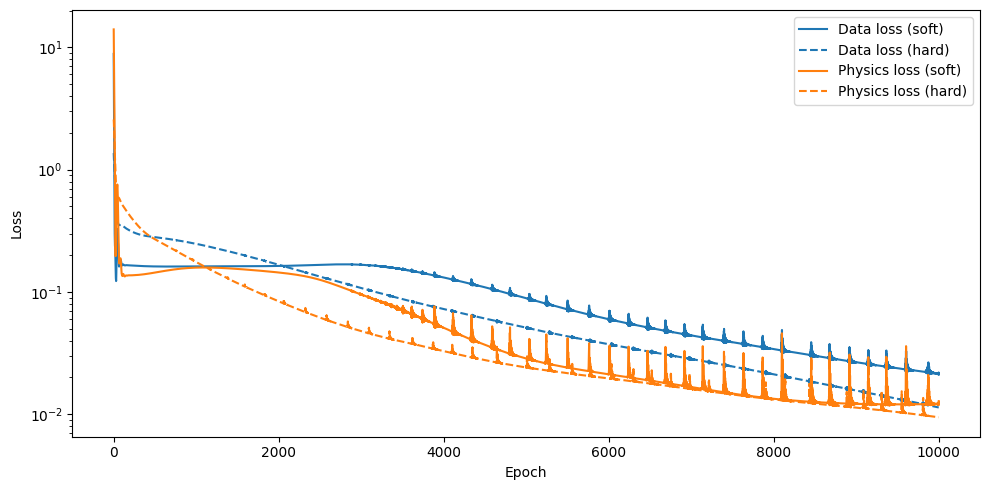

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(data_losses, color="tab:blue",
         label="Data loss (soft)")

plt.plot(data_losses_hard, "--", color="tab:blue",
         label="Data loss (hard)")

plt.plot(phys_losses, color="tab:orange",
         label="Physics loss (soft)")

plt.plot(phys_losses_hard, "--", color="tab:orange",
         label="Physics loss (hard)")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Nu laver vi en funktion der træner et netværk for givne regularization vægt (lambda) og returnerer det trænede netværk så vi kan bruge de trænede netværk til forudsigelser.

def train_pinn_hard(data_input, data_target, colloc_input, lambda_phys, num_epochs=10000):
    torch.manual_seed(42) #vi sørger for at de bliver initialiset ens
    net = Net()
    optimizer = optim.Adam(net.parameters(), lr=0.005)
    
    # Training loop
    for e in range(num_epochs):

        optimizer.zero_grad()

        with torch.no_grad():
            # Calculate loss. (vha. den loss funktion vi definerede tidligere)
            L_data, L_phys, tr_loss = loss_hard(
                net, data_input, data_target, colloc_input, lambda_phys
            )

            # Calculate analytical gradients
            g_total_W1, g_total_W2, g_total_b1, g_total_b2 = analytical_grads_hard(
                net, data_input, data_target, colloc_input, lambda_phys
            )

        # Give the gradients to the optimizer
        net.W_1.grad = g_total_W1
        net.W_2.grad = g_total_W2
        net.b_1.grad = g_total_b1
        net.b_2.grad = g_total_b2

        # Update weights
        optimizer.step()
    return net

In [ ]:
# Nu der prøver vi så at træne for to forskellige værdier af lambda_phys (en stor og en lille))
lambda_phys_weak_hard= 0.00000001
lambda_phys_strong_hard= 0.00001
net_weak_hard= train_pinn_hard(data_input, data_target, colloc_input, lambda_phys_weak_hard, num_epochs)
net_strong_hard= train_pinn_hard(data_input, data_target, colloc_input, lambda_phys_strong_hard, num_epochs)

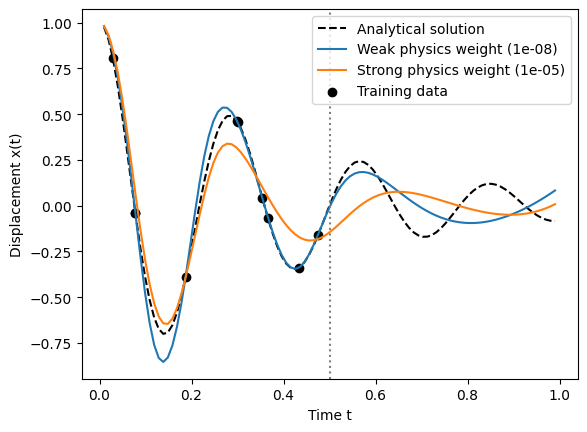

In [ ]:
te_target = torch.from_numpy(plotting_data[1]).float().reshape(-1, 1)
te_input= torch.from_numpy(plotting_data[0]).float().reshape(-1, 1)

# så bruger vi de to trænede netværk til at lave forudsigelser på test dataen og sammenligner med den sande test data te_target.
with torch.no_grad():
    te_output_weak_hard = net_weak_hard(te_input).numpy().reshape(-1)
    te_output_strong_hard = net_strong_hard(te_input).numpy().reshape(-1)

t= te_input.numpy().reshape(-1)

# og plot den analytiske løsning, de to forudsigelser og træningsdataen.
plt.plot(t, te_target, "k--", label="Analytical solution")
plt.plot(t, te_output_weak_hard*t**2+1, label="Weak physics weight (%g)" % lambda_phys_weak_hard)
plt.plot(t, te_output_strong_hard*t**2+1, label="Strong physics weight (%g)" % lambda_phys_strong_hard)
plt.scatter(data_hard_data[0], data_hard_data[1], color="black", label="Training data")
plt.axvline(0.5, color="gray", linestyle=":")
plt.xlabel("Time t")
plt.ylabel("Displacement x(t)")
plt.legend()
plt.show()